# Analysis — `second_test` experiment

Reconstruction of the analyses summarized in `SESSION_NOTES.md`.

**Source:** `data/multi_run/output/20260416_225546_scenario_second_test/results.csv` (10,000 runs = 100 scenarios × 100 policies).

**Scenario:** 1 brigade × 2 battalions, 18 CCPs, 2 R1s, 4 CCP→R1 ambulances, no Role 2/AXPs.

## 0. Setup

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.model_selection import cross_val_score

RUN_DIR = Path('..') / 'data' / 'multi_run' / 'output' / '20260416_225546_scenario_second_test'
assert RUN_DIR.exists(), f'{RUN_DIR} not found — adjust path'

df = pd.read_csv(RUN_DIR / 'results.csv')
print(df.shape)
df.head()

(10000, 46)


,bcas_rate,dcr_capacity,n_battalions_in_combat,pec_capacity,seed,wave_duration_min,waves_per_day,amb_speed_ccp_r1,ambulance_eligibility,facility_eligibility,...,waiting_transport_ccp_t3_bcas_pec,waiting_care_dcr_t1_bcas_dcr,waiting_care_dcr_t2_bcas_dcr,waiting_care_pec_t3_bcas_pec,transit_ccp_role1_t1_bcas_dcr,transit_ccp_role1_t2_bcas_dcr,transit_ccp_role1_t3_bcas_pec,in_care_dcr_t1_bcas_dcr,in_care_dcr_t2_bcas_dcr,in_care_pec_t3_bcas_pec
0,0.074757,2,2,3,3109,211,5,3,1,0,...,1241.183009,0.0,0.0,0.365699,0.0,140.0,140.0,0.0,27.631841,27.492905
1,0.092866,10,2,6,4632,72,2,3,1,0,...,1167.188355,0.0,0.0,0.000000,0.0,140.0,140.0,0.0,27.494029,27.477362
2,0.083484,4,1,5,6790,79,6,3,1,0,...,459.685875,0.0,0.0,1.616004,0.0,140.0,140.0,0.0,27.382511,27.503245
3,0.025407,3,1,10,5347,132,3,3,1,0,...,211.157202,0.0,0.0,0.000000,0.0,140.0,140.0,0.0,27.559439,27.496955
4,0.010289,6,2,9,1817,43,1,3,1,0,...,301.951883,0.0,0.0,0.000000,0.0,140.0,140.0,0.0,27.358414,27.357745


In [6]:
UNCERTAINTIES = [
    'bcas_rate', 'waves_per_day', 'wave_duration_min', 'n_battalions_in_combat',
    'dcr_capacity', 'pec_capacity',
]
LEVERS = [
    'n_amb_r1_to_ccp', 'amb_speed_ccp_r1', 'r1_closest_km', 'r1_second_km',
    'facility_eligibility', 'ambulance_eligibility',
]
FEATURES = UNCERTAINTIES + LEVERS

OUTCOMES_SCALAR = [
    'death_rate', 'safe_rate',
    'death_rate_T1_BCAS', 'death_rate_T2_BCAS', 'death_rate_T3_BCAS',
    'mean_wait_transport_T1_BCAS', 'mean_wait_transport_T2_BCAS', 'mean_wait_transport_T3_BCAS',
    'mean_wait_care_T1_BCAS', 'mean_wait_care_T2_BCAS', 'mean_wait_care_T3_BCAS',
    'total_transport_time',
]

## 1. Feature scoring (Extra Trees)

Which inputs drive each outcome? We use the `feature_importances_` from `ExtraTreesRegressor` as a proxy for variance explained, fit per outcome.

In [7]:
def feature_score_matrix(inputs: pd.DataFrame, outcomes: pd.DataFrame, n_estimators: int = 250) -> pd.DataFrame:
    """Returns a DataFrame (features × outcomes) of ExtraTrees feature importances."""
    scores = {}
    for col in outcomes.columns:
        y = outcomes[col].values
        mask = ~np.isnan(y)
        if mask.sum() < 50:
            continue
        et = ExtraTreesRegressor(n_estimators=n_estimators, random_state=42, n_jobs=-1)
        et.fit(inputs.values[mask], y[mask])
        scores[col] = et.feature_importances_
    return pd.DataFrame(scores, index=inputs.columns)


def plot_feature_scores(scores: pd.DataFrame, title: str, fname: Path = None) -> None:
    fig, ax = plt.subplots(figsize=(max(6, 0.5*len(scores.columns)), 0.4*len(scores.index) + 2))
    sns.heatmap(scores, annot=True, fmt='.2f', cmap='viridis', ax=ax, cbar_kws={'label': 'importance'})
    ax.set_title(title)
    plt.tight_layout()
    if fname:
        plt.savefig(fname, dpi=120)
    plt.show()

### 1a. Full input range
Speed dominates — because the sweep is 1–50 km/h, any outcome touching transport is overwhelmed by this one factor.

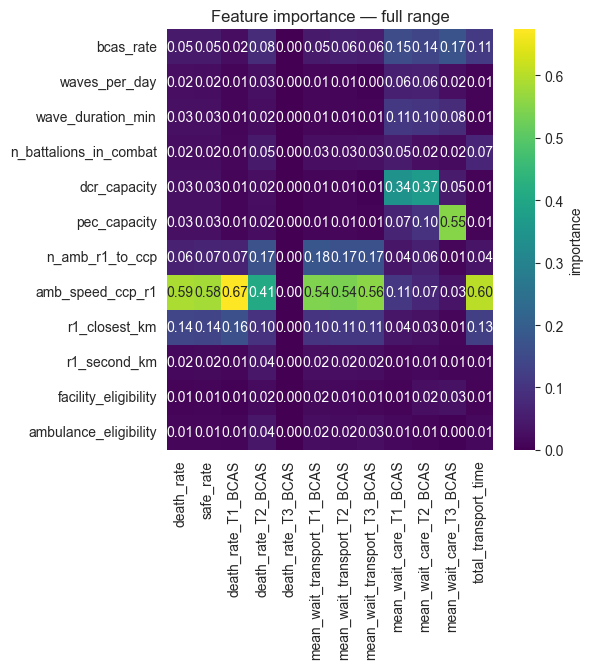

In [8]:
inputs_full = df[FEATURES]
outcomes_sel = df[OUTCOMES_SCALAR]
scores_full = feature_score_matrix(inputs_full, outcomes_sel)
plot_feature_scores(scores_full, 'Feature importance — full range', RUN_DIR / 'feature_scores.png')

### 1b. Collapse speed + distance → transport time

Derived variable `transport_time_ccp_r1_closest = r1_closest_km / amb_speed_ccp_r1 * 60` (minutes). Replaces the raw speed and distance features.

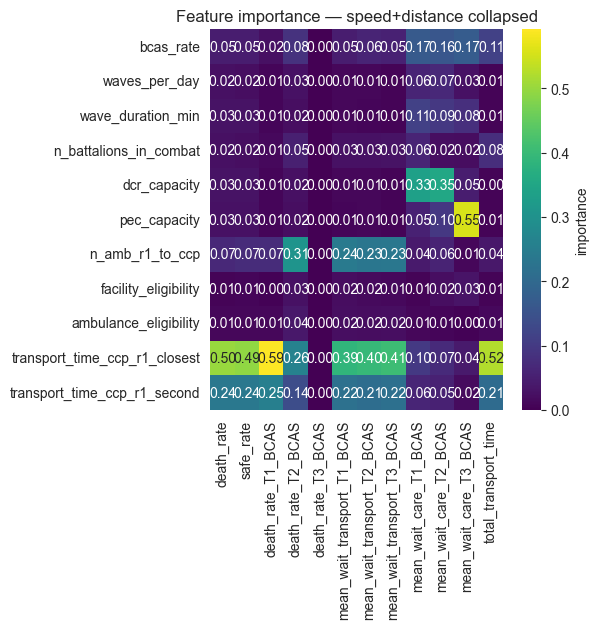

In [9]:
df['transport_time_ccp_r1_closest'] = df['r1_closest_km'] / df['amb_speed_ccp_r1'] * 60.0
df['transport_time_ccp_r1_second'] = df['r1_second_km'] / df['amb_speed_ccp_r1'] * 60.0

FEATURES_COMPOUND = [
    *UNCERTAINTIES,
    'n_amb_r1_to_ccp', 'facility_eligibility', 'ambulance_eligibility',
    'transport_time_ccp_r1_closest', 'transport_time_ccp_r1_second',
]

scores_compound = feature_score_matrix(df[FEATURES_COMPOUND], outcomes_sel)
plot_feature_scores(scores_compound, 'Feature importance — speed+distance collapsed', RUN_DIR / 'feature_scores_transport_time.png')

### 1c. Realistic-speed filter (25–35 km/h)

Constrain the sample to realistic ambulance speeds to stop speed from drowning out everything else.

N realistic = 2200


C:\Users\User\AppData\Local\Temp\ipykernel_18224\3356310755.py:19: UserWarning: Glyph 8712 (\N{ELEMENT OF}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\User\AppData\Local\Temp\ipykernel_18224\3356310755.py:21: UserWarning: Glyph 8712 (\N{ELEMENT OF}) missing from font(s) Arial.
  plt.savefig(fname, dpi=120)
C:\Users\User\Documents\thesis\medevac_model\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8712 (\N{ELEMENT OF}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


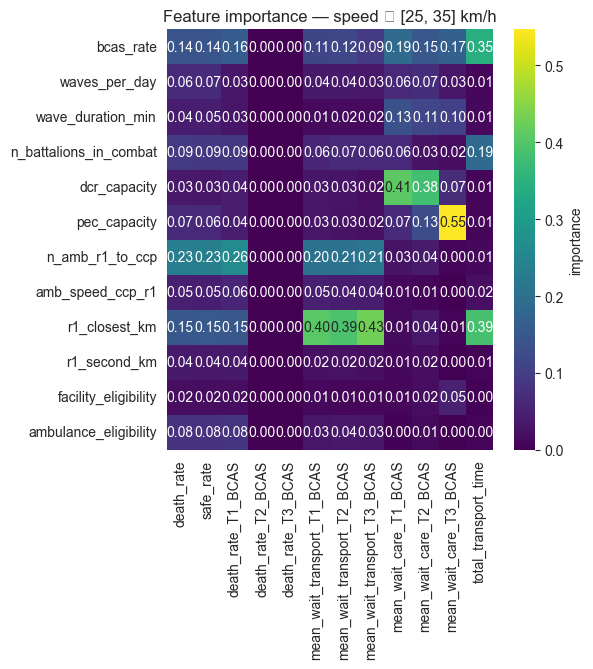

In [10]:
realistic = df[(df['amb_speed_ccp_r1'] >= 25) & (df['amb_speed_ccp_r1'] <= 35)].reset_index(drop=True)
print(f'N realistic = {len(realistic)}')

scores_fixed_speed = feature_score_matrix(realistic[FEATURES], realistic[OUTCOMES_SCALAR])
plot_feature_scores(scores_fixed_speed, 'Feature importance — speed ∈ [25, 35] km/h', RUN_DIR / 'feature_scores_fixed_speed.png')

## 2. Random Forest for wait-for-transport

Polynomial regression plateaued at R²≈0.35 (deg 2) because of the skewed, threshold-driven wait-time distribution. A Random Forest reaches R²≈0.75.

In [ ]:
rf_results = []
for tgt in ['mean_wait_transport_T1_BCAS', 'mean_wait_transport_T2_BCAS', 'mean_wait_transport_T3_BCAS']:
    mask = df[tgt].notna()
    X = df.loc[mask, FEATURES].values
    y = df.loc[mask, tgt].values
    rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42)
    r2 = cross_val_score(rf, X, y, cv=5, scoring='r2')
    mae = -cross_val_score(rf, X, y, cv=5, scoring='neg_mean_absolute_error')
    rf.fit(X, y)
    imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False)
    rf_results.append({'target': tgt, 'r2_mean': r2.mean(), 'r2_std': r2.std(), 'mae_mean': mae.mean(), 'importances': imp})
    print(f'{tgt}: R2={r2.mean():.3f}±{r2.std():.3f}  MAE={mae.mean():.1f}±{mae.std():.1f} min')

# Display importances as a DataFrame
pd.DataFrame({r['target']: r['importances'] for r in rf_results}).round(3)

## 3. Patient lifecycle — stacked bars

Per triage, average time spent in (1) waiting for transport at CCP, (2) transit CCP→R1, (3) waiting for care, (4) in care.

In [ ]:
PHASE_MAP = {
    'T1': ('waiting_transport_ccp_t1_bcas_dcr', 'transit_ccp_role1_t1_bcas_dcr', 'waiting_care_dcr_t1_bcas_dcr', 'in_care_dcr_t1_bcas_dcr'),
    'T2': ('waiting_transport_ccp_t2_bcas_dcr', 'transit_ccp_role1_t2_bcas_dcr', 'waiting_care_dcr_t2_bcas_dcr', 'in_care_dcr_t2_bcas_dcr'),
    'T3': ('waiting_transport_ccp_t3_bcas_pec', 'transit_ccp_role1_t3_bcas_pec', 'waiting_care_pec_t3_bcas_pec', 'in_care_pec_t3_bcas_pec'),
}
PHASE_LABELS = ['wait transport', 'transit CCP→R1', 'wait care', 'in care']
PHASE_COLORS = ['#d62728', '#ff7f0e', '#1f77b4', '#2ca02c']

def lifecycle_bars(df_subset: pd.DataFrame, title: str, fname: Path = None):
    rows = []
    for triage, cols in PHASE_MAP.items():
        rows.append([df_subset[c].mean() for c in cols])
    means = pd.DataFrame(rows, index=list(PHASE_MAP.keys()), columns=PHASE_LABELS)

    fig, ax = plt.subplots(figsize=(6, 4.5))
    bottom = np.zeros(len(means))
    for i, ph in enumerate(PHASE_LABELS):
        ax.bar(means.index, means[ph], bottom=bottom, color=PHASE_COLORS[i], label=ph)
        bottom += means[ph].values
    ax.set_ylabel('Mean time (min)')
    ax.set_title(title)
    ax.legend(loc='upper right', fontsize=9)
    plt.tight_layout()
    if fname:
        plt.savefig(fname, dpi=120)
    plt.show()
    return means

# All runs — shows survivorship bias (T1 transit < T2 transit)
lifecycle_bars(df, 'Patient lifecycle — all runs (survivorship-biased)', RUN_DIR / 'patient_lifecycle_stacked.png')

In [ ]:
# Matched runs — both T1 and T2 transit present (no survivorship dropout)
matched = df[df['transit_ccp_role1_t1_bcas_dcr'].notna() & df['transit_ccp_role1_t2_bcas_dcr'].notna()]
print(f'Matched N = {len(matched)}')
lifecycle_bars(matched, 'Patient lifecycle — matched runs', RUN_DIR / 'patient_lifecycle_stacked_matched.png')

## 4. Mortality distributions

T1 mortality is **bimodal**: system either rescues all T1 or loses them all. ~30 min wait is the cliff.

In [ ]:
def plot_mortality_dists(subset: pd.DataFrame, title: str, fname: Path = None):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
    for ax, col, lbl in zip(axes, ['death_rate_T1_BCAS', 'death_rate_T2_BCAS'], ['T1', 'T2']):
        s = subset[col].dropna()
        ax.hist(s, bins=20, color='#d62728' if lbl == 'T1' else '#ff7f0e', edgecolor='black', alpha=0.8)
        ax.set_xlabel(f'{lbl} death rate')
        ax.set_ylabel('Runs')
        ax.set_title(f'{lbl} BCAS — N={len(s)}')
    fig.suptitle(title)
    plt.tight_layout()
    if fname:
        plt.savefig(fname, dpi=120)
    plt.show()

plot_mortality_dists(df, 'Mortality distribution — all runs', RUN_DIR / 'mortality_distribution_t1_t2.png')

In [ ]:
above5 = df[df['bcas_rate'] > 0.05]
print(f'N with bcas_rate > 5% = {len(above5)}')
plot_mortality_dists(above5, 'Mortality distribution — bcas_rate > 5%', RUN_DIR / 'mortality_distribution_t1_t2_above5pct.png')

In [ ]:
# Patient counts (for reference)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, col, lbl in zip(axes, ['n_patients_T1_BCAS', 'n_patients_T2_BCAS'], ['T1', 'T2']):
    ax.hist(df[col].dropna(), bins=30, color='#1f77b4', edgecolor='black', alpha=0.8)
    ax.set_xlabel(f'{lbl} patient count per run'); ax.set_ylabel('Runs'); ax.set_title(lbl)
fig.suptitle('Patient counts per run')
plt.tight_layout()
plt.savefig(RUN_DIR / 'patient_count_distribution_t1_t2.png', dpi=120)
plt.show()

In [ ]:
# T1 count in runs where all T1 died (to check whether bimodality is a sample-size artifact)
all_dead = df[df['death_rate_T1_BCAS'] == 1.0]
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(all_dead['n_patients_T1_BCAS'].dropna(), bins=30, color='#8c564b', edgecolor='black')
ax.set_xlabel('Number of T1 patients')
ax.set_ylabel('Runs')
ax.set_title(f'T1 patient counts in runs where 100% died (N={len(all_dead)})')
plt.tight_layout()
plt.savefig(RUN_DIR / 't1_count_when_all_dead.png', dpi=120)
plt.show()

### T1 mortality vs wait-for-transport (boxplot by bins)

In [ ]:
wait_col = 'mean_wait_transport_T1_BCAS'
death_col = 'death_rate_T1_BCAS'
sub = df[[wait_col, death_col]].dropna()

bin_edges = [0, 10, 20, 30, 45, 60, 90, 120, 180, 240, np.inf]
bin_labels = ['0-10', '10-20', '20-30', '30-45', '45-60', '60-90', '90-120', '120-180', '180-240', '>240']
sub['wait_bin'] = pd.cut(sub[wait_col], bins=bin_edges, labels=bin_labels, include_lowest=True)

groups = [sub.loc[sub['wait_bin'] == b, death_col].values for b in bin_labels]
present = [(b, g) for b, g in zip(bin_labels, groups) if len(g) > 0]
lbls = [b for b, _ in present]
data = [g for _, g in present]

fig, ax = plt.subplots(figsize=(10, 5))
bp = ax.boxplot(data, labels=lbls, patch_artist=True, showmeans=True)
for patch in bp['boxes']:
    patch.set_facecolor('#d62728'); patch.set_alpha(0.6)
ax.set_xlabel('Mean T1 wait-for-transport (min)')
ax.set_ylabel('T1 death rate')
ax.set_title('T1 mortality vs wait-for-transport — ~30 min cliff')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(RUN_DIR / 't1_mortality_vs_wait_boxplot.png', dpi=120)
plt.show()

## 5. Distance threshold at realistic speeds (with / without pooling)

Filter to `amb_speed_ccp_r1 ∈ [25, 30]` and plot death rate vs `r1_closest_km` for strict vs loose ambulance eligibility.

In [ ]:
spd = df[(df['amb_speed_ccp_r1'] >= 25) & (df['amb_speed_ccp_r1'] <= 30)]
print(f'N at realistic speed = {len(spd)}')

fig, ax = plt.subplots(figsize=(8, 5))
for amb_elig, color, lbl in [(0, '#d62728', 'strict (no pooling)'), (1, '#2ca02c', 'loose (pooling)')]:
    s = spd[spd['ambulance_eligibility'] == amb_elig]
    agg = s.groupby('r1_closest_km')['death_rate_T1_BCAS'].agg(['mean', 'count']).reset_index()
    ax.plot(agg['r1_closest_km'], agg['mean'], marker='o', color=color, label=f'{lbl} (N per point: {agg["count"].min()}-{agg["count"].max()})')
ax.set_xlabel('r1_closest_km')
ax.set_ylabel('T1 death rate (mean over runs)')
ax.set_title('T1 mortality vs closest-R1 distance — speed 25–30 km/h')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(RUN_DIR / 'mortality_vs_distance_pooling.png', dpi=120)
plt.show()

## 6. PRIM scenario discovery

Question: *in which scenario subspace does each policy lever create the biggest mortality reduction?*

Approach: for each scenario (uncertainty combination), compute the mean death-rate benefit from turning the lever on. Then PRIM the benefit against the uncertainty dimensions.

In [ ]:
from ema_workbench.analysis import prim

def pooling_benefit_df(source: pd.DataFrame, lever_col: str, outcome: str = 'death_rate') -> pd.DataFrame:
    """Per-scenario benefit of lever=1 vs lever=0, joined with that scenario's uncertainty values."""
    off = source[source[lever_col] == 0].groupby('scenario')[outcome].mean()
    on  = source[source[lever_col] == 1].groupby('scenario')[outcome].mean()
    benefit = (off - on).rename('benefit')
    unc = source.groupby('scenario')[UNCERTAINTIES + ['amb_speed_ccp_r1', 'r1_closest_km']].first()
    return unc.join(benefit).dropna().reset_index(drop=True)

def run_prim(bdf: pd.DataFrame, threshold: float, title: str, fname: Path = None):
    x = bdf.drop(columns=['benefit'])
    y = (bdf['benefit'] > threshold).astype(int)
    print(f'Target rate = {y.mean():.3f}  (threshold benefit > {threshold})')
    alg = prim.Prim(x, y, threshold=0.7, peel_alpha=0.1)
    box = alg.find_box()
    box.show_tradeoff()
    if fname:
        plt.title(title)
        plt.savefig(fname, dpi=120)
    plt.show()
    return box

In [ ]:
# Ambulance pooling benefit
pb = pooling_benefit_df(df, 'ambulance_eligibility')
print(pb['benefit'].describe())
run_prim(pb, threshold=pb['benefit'].quantile(0.75), title='PRIM — ambulance pooling benefit', fname=RUN_DIR / 'prim_pooling_benefit.png')

In [ ]:
# Facility pooling benefit
fb = pooling_benefit_df(df, 'facility_eligibility')
print(fb['benefit'].describe())
run_prim(fb, threshold=fb['benefit'].quantile(0.75), title='PRIM — facility pooling benefit', fname=RUN_DIR / 'prim_facility_pooling_benefit.png')

In [ ]:
# Fleet size benefit — 3 bins (small/medium/large) of n_amb_r1_to_ccp
bins = pd.cut(df['n_amb_r1_to_ccp'], bins=[0, 3, 6, 10], labels=['small', 'medium', 'large'])
df['_fleet_bin'] = bins

small = df[df['_fleet_bin'] == 'small'].groupby('scenario')['death_rate'].mean()
large = df[df['_fleet_bin'] == 'large'].groupby('scenario')['death_rate'].mean()
benefit = (small - large).rename('benefit')
unc = df.groupby('scenario')[UNCERTAINTIES + ['amb_speed_ccp_r1', 'r1_closest_km']].first()
fleet_benefit = unc.join(benefit).dropna().reset_index(drop=True)

run_prim(fleet_benefit, threshold=fleet_benefit['benefit'].quantile(0.75),
         title='PRIM — fleet size benefit (large vs small)', fname=RUN_DIR / 'prim_fleet_benefit.png')

## Summary

See [SESSION_NOTES.md](../data/multi_run/output/20260416_225546_scenario_second_test/SESSION_NOTES.md) for the narrative interpretation of every plot above.